In [ ]:
from config import Config, NetworkKind
from lib import SweepPoint, sweep
from plot import plot_grid_search

results = {}


In [ ]:
STEP_SIZE = 4
n_agents = Config().n_agents
seeds = range(100)

results[NetworkKind.RANDOM] = sweep(
    NetworkKind.RANDOM,
    [SweepPoint(p_edge=step / 20) for step in range(1, 21)],
    seeds,
)
plot_grid_search(results[NetworkKind.RANDOM], "p_edge")


In [ ]:
results[NetworkKind.BARBASI] = sweep(
    NetworkKind.BARBASI,
    [SweepPoint(edges=edges) for edges in range(STEP_SIZE, n_agents, STEP_SIZE)],
    seeds,
)
plot_grid_search(results[NetworkKind.BARBASI], "edges")


In [ ]:
results[NetworkKind.WATTS] = sweep(
    NetworkKind.WATTS,
    [
        SweepPoint(k_neighbors=neighbors, p_rewire=step / 20)
        for neighbors in range(STEP_SIZE, n_agents, STEP_SIZE)
        for step in range(21)
    ],
    seeds,
)
plot_grid_search(results[NetworkKind.WATTS], "k_neighbors", "p_rewire")


In [ ]:
for kind, summary in results.items():
    print(kind)
    print(summary)


In [ ]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

random_vs_barbasi = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.BARBASI].seed_means,
)
random_vs_watts = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
barbasi_vs_watts = ttest_rel(
    results[NetworkKind.BARBASI].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
adjusted = multipletests(
    [random_vs_barbasi.pvalue, random_vs_watts.pvalue, barbasi_vs_watts.pvalue],
    method="holm",
)[1]
print("random vs barbasi:", random_vs_barbasi, "Holm p:", adjusted[0])
print("random vs watts:", random_vs_watts, "Holm p:", adjusted[1])
print("barbasi vs watts:", barbasi_vs_watts, "Holm p:", adjusted[2])


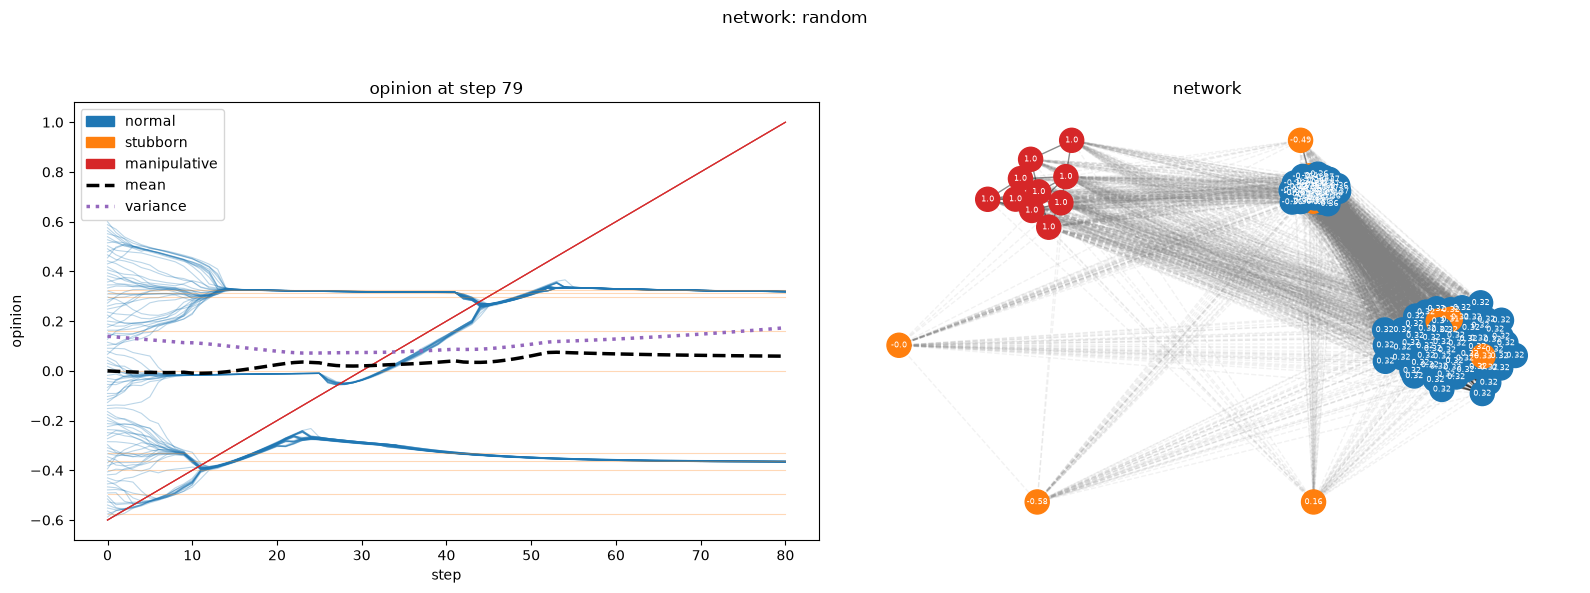

<Figure size 640x480 with 0 Axes>

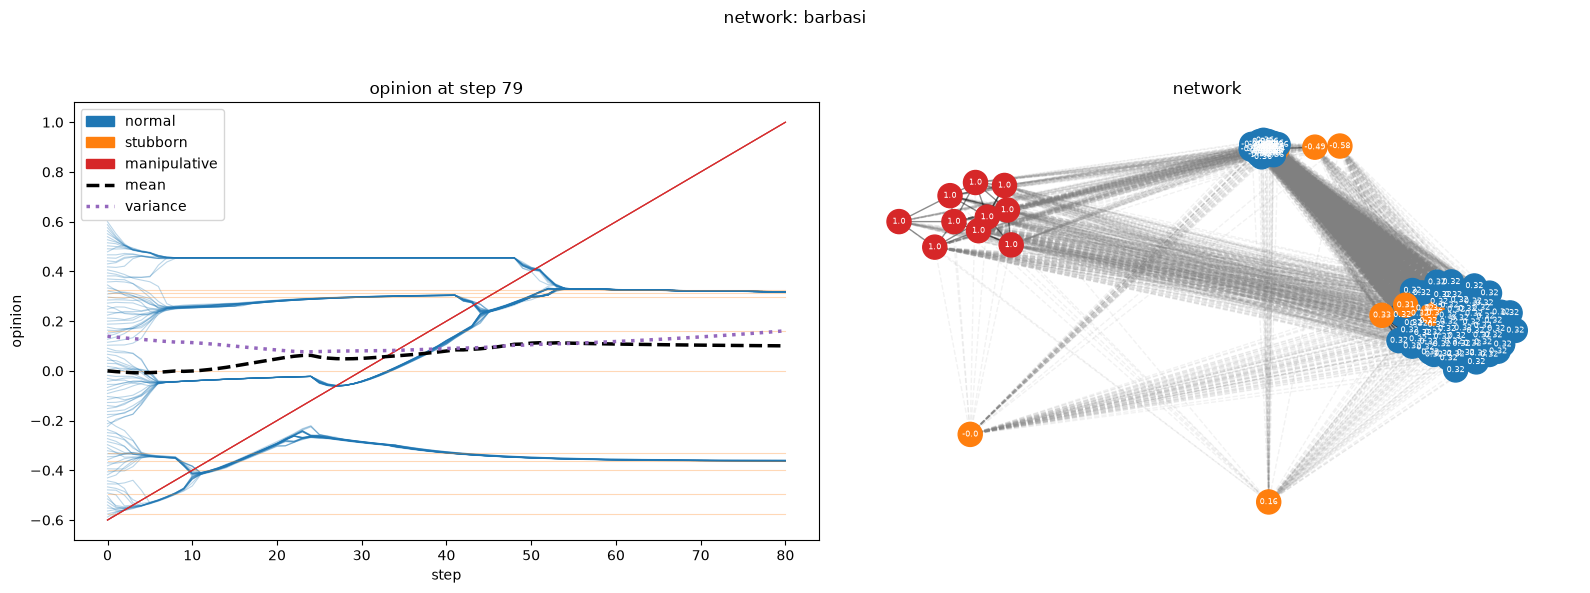

<Figure size 640x480 with 0 Axes>

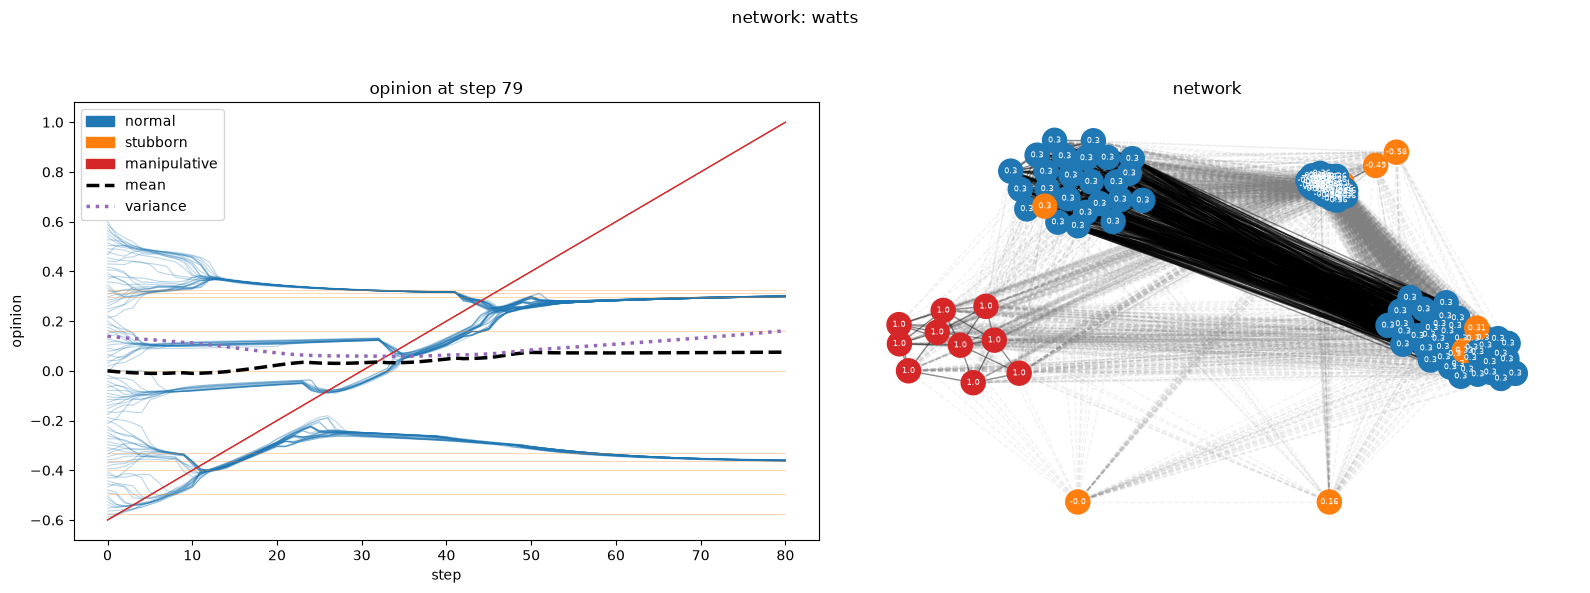

<Figure size 640x480 with 0 Axes>

In [1]:
from config import Config
from lib import init_sim, run_one

cfg = Config()
cfg.seed = 10
for kind in cfg.networks:
    sim = init_sim(cfg, kind)
    run_one(cfg, sim, True)
